# 04 · Research Release 1: choose a hedge under a cost budget

**Question:** can an adaptive delta-band policy offer useful incremental protection while respecting a pre-specified expected stock-cost budget?

This notebook reads the frozen protocol, locked selection and held-out results from the controlled research release. The three-name `Book` remains the validated model container. No FMP credentials or market data are needed for this synthetic release.

The default protocol has fourteen periodic/fixed-band/maturity-band candidates, a $500 expected financed stock-cost budget for $300,000 underlying notional, 5,000 selection paths and 10,000 evaluation paths. Selection and evaluation use distinct seeds. The choice is persisted before evaluation, and is not retuned using the evaluation table.

Human review follows this automated pass. This notebook's gate is a controlled simulation result, not a claim of empirical forecast improvement or executable listed-option performance.

In [1]:
from pathlib import Path
from hashlib import sha256
from datetime import datetime, timezone
import sys
import json

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "hedging_harness" / "research.py").is_file():
    ROOT = ROOT.parent
assert (ROOT / "hedging_harness" / "research.py").is_file()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from hedging_harness.research import load_protocol, run_release

PROTOCOL = ROOT / "config" / "research_release_1.json"
RELEASE_DIR = ROOT / "results" / "research-release-1" / "release-1"
RUN_NEW_EXPERIMENT = False

## 1 · Inspect the pre-specified decisions

A fixed delta band trades when absolute stock-hedge discrepancy divided by option units exceeds the threshold. The maturity band multiplies its initial threshold by the square root of remaining maturity divided by original maturity.

Opening and settlement are unconditional. All choices operate only on current observations. The budget screen uses the upper endpoint of a two-sided 95% normal interval for expected financed trading cost, rather than a cap on every individual outcome.

In [2]:
spec, book, scenario, policies, study_path = load_protocol(PROTOCOL)
print(spec["research_question"])
print(f"Expected financed cost budget: ${spec['cost_budget_dollars']:,.0f}; one-way stock charge: {spec['cost_bps']:g} bp")
print(f"Selection: {spec['selection']}; evaluation: {spec['evaluation']}")
display(pd.DataFrame(spec["candidates"]).fillna("not used"))

How much incremental protection do adaptive delta hedges buy under an expected financed trading-cost budget?
Expected financed cost budget: $500; one-way stock charge: 5 bp
Selection: {'seed': 730201, 'n_paths': 5000}; evaluation: {'seed': 730202, 'n_paths': 10000}


/var/folders/fv/8kgvjzz53_s0kstrbq5d16vw0000gn/T/ipykernel_8761/1267954560.py:5: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(pd.DataFrame(spec["candidates"]).fillna("not used"))


,label,kind,hedge_every,band
0,initial_only,periodic,not used,not used
1,daily,periodic,1.0,not used
2,two_day,periodic,2.0,not used
3,weekly,periodic,5.0,not used
4,delta_band_010,delta_band,not used,0.01
5,delta_band_025,delta_band,not used,0.025
6,delta_band_050,delta_band,not used,0.05
7,delta_band_075,delta_band,not used,0.075
8,delta_band_100,delta_band,not used,0.1
9,delta_band_150,delta_band,not used,0.15


## 2 · Reuse the committed release or explicitly run a new experiment

The default reads the existing locked release and verifies every artifact checksum. If the artifact directory is absent, the protocol is executed once. Set `RUN_NEW_EXPERIMENT=True` to write a separate timestamped replication; existing release directories are never overwritten.

A new run follows the same frozen selection rule and independent-sample structure. Changing candidate rules, budget or inputs is a new protocol and should be labelled separately.

In [3]:
if RUN_NEW_EXPERIMENT or not (RELEASE_DIR / "gate_status.json").is_file():
    if RELEASE_DIR.exists():
        stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
        RELEASE_DIR = ROOT / "results" / "research-release-1" / stamp
    run_release(PROTOCOL, RELEASE_DIR)

commitment = json.loads((RELEASE_DIR / "protocol_commitment.json").read_text())
if commitment["protocol_sha256"] != sha256(PROTOCOL.read_bytes()).hexdigest():
    raise ValueError("Cached results use a different protocol. Set RUN_NEW_EXPERIMENT=True to run the changed protocol separately.")
if commitment["study_sha256"] != sha256(study_path.read_bytes()).hexdigest():
    raise ValueError("Cached results use different study inputs. Set RUN_NEW_EXPERIMENT=True for a separate run.")
manifest = json.loads((RELEASE_DIR / "artifact_manifest.json").read_text())
for name, expected_hash in manifest.items():
    assert sha256((RELEASE_DIR / name).read_bytes()).hexdigest() == expected_hash, name
selection_lock = json.loads((RELEASE_DIR / "selection.json").read_text())
gate = json.loads((RELEASE_DIR / "gate_status.json").read_text())
assert gate["status"] == "complete"
assert sha256((RELEASE_DIR / "selection.json").read_bytes()).hexdigest() == gate["selection_lock_sha256"]
selected = selection_lock["selected_policy"]
selection = pd.read_csv(RELEASE_DIR / "selection_metrics.csv")
evaluation = pd.read_csv(RELEASE_DIR / "evaluation_metrics.csv")
print(f"Verified release: {RELEASE_DIR}")
print(f"Locked policy: {selected}")

Verified release: /Users/saireddivari/MonteCarloEvaluations/results/research-release-1/release-1
Locked policy: maturity_band_050


## 3 · Separate policy selection from evaluation

The selection table alone determines the chosen policy: minimum ES95 among candidates whose expected-cost upper endpoint is within budget. The evaluation table shows performance on different realized stock paths. Evaluation budget feasibility is reported without changing the selected rule.

The tables include mean P&L/SE, residual risk, execution costs, turnover and concurrent portfolio peak borrowing. Negative mean P&L includes costs already; do not subtract them again.

In [4]:
columns = ["policy", "loss_es95", "pnl_std", "mean_pnl", "mean_financed_cost", "cost_mean_upper", "budget_feasible"]
print("Selection sample:")
display(selection[columns].round(4))
print("Held-out evaluation sample:")
display(evaluation[columns].round(4))
print("Locked-policy evaluation:")
display(evaluation.loc[evaluation["policy"].eq(selected), columns].round(4))

Selection sample:


,policy,loss_es95,pnl_std,mean_pnl,mean_financed_cost,cost_mean_upper,budget_feasible
0,initial_only,22363.6803,8510.0323,-7.4228,168.7415,168.9945,True
1,daily,3427.8330,1227.1093,-583.5271,546.7941,549.9653,False
2,two_day,4319.1553,1701.2165,-465.5792,438.1944,440.7820,True
3,weekly,6317.9236,2587.2410,-379.7515,336.7741,338.8453,True
4,delta_band_010,3421.2406,1228.7754,-574.7152,539.1611,542.3420,False
5,delta_band_025,3406.2591,1249.3836,-548.0679,513.1946,516.3432,False
6,delta_band_050,3441.3345,1334.6647,-481.5633,458.5600,461.5158,True
7,delta_band_075,3599.0894,1479.1450,-426.8489,410.9432,413.6728,True
8,delta_band_100,4031.1277,1721.5599,-380.8931,373.8376,376.3487,True
9,delta_band_150,5108.1759,2178.5217,-342.7775,323.1055,325.2843,True


Held-out evaluation sample:


,policy,loss_es95,pnl_std,mean_pnl,mean_financed_cost,cost_mean_upper,budget_feasible
0,initial_only,23084.4590,8582.2368,-150.2791,168.9143,169.0956,True
1,daily,3326.0459,1207.9573,-533.8898,545.6913,547.9272,False
2,two_day,4242.3455,1686.5809,-404.9949,437.6281,439.4465,True
3,weekly,6242.9035,2585.7832,-305.2883,336.1342,337.5921,True
4,delta_band_010,3319.2298,1209.3911,-525.9631,538.0572,540.3001,False
5,delta_band_025,3300.2642,1226.5982,-498.4537,512.0822,514.2995,False
6,delta_band_050,3390.9499,1318.7679,-445.6164,457.6122,459.6945,True
7,delta_band_075,3658.8631,1484.9381,-391.8509,410.1016,412.0206,True
8,delta_band_100,4064.4444,1709.1343,-359.6710,373.5452,375.3168,True
9,delta_band_150,5166.8778,2186.2523,-298.2189,322.3708,323.9095,True


Locked-policy evaluation:


,policy,loss_es95,pnl_std,mean_pnl,mean_financed_cost,cost_mean_upper,budget_feasible
12,maturity_band_050,3327.9446,1256.8025,-474.64,487.9714,490.1775,True


## 4 · Quantify incremental protection

The paired-tail table is `ES95(selected) - ES95(benchmark)`: negative values favor the selected rule. Bootstrap resamples use the same economic-outcome indices for both policies, recomputing each policy's own tail each time. This is not ES of the P&L difference.

Intervals are pointwise and conditional on the fixed model, not a simultaneous dominance statement. An interval covering zero is inconclusive for superiority; it does not establish equivalence or non-inferiority without a pre-specified margin.

The separate mean table is `mean P&L(selected) - mean P&L(benchmark)`. Its interval concerns the average, not tail precision.

In [5]:
tail_differences = pd.read_csv(RELEASE_DIR / "paired_tail_differences.csv")
mean_differences = pd.read_csv(RELEASE_DIR / "paired_mean_differences.csv")
print("Paired ES95 differences:")
display(tail_differences[["benchmark", "estimate", "lower", "upper", "bootstrap_se"]].round(4))
print("Paired mean-P&L differences:")
display(mean_differences.round(4))
print("Selected-policy economic-risk intervals:")
display(pd.DataFrame(json.loads((RELEASE_DIR / "selected_risk_intervals.json").read_text())).round(4))

Paired ES95 differences:


,benchmark,estimate,lower,upper,bootstrap_se
0,initial_only,-19756.5143,-20479.0102,-19020.9977,369.0978
1,daily,1.8987,-31.6143,33.5638,16.8605
2,two_day,-914.4008,-1013.4084,-809.4764,53.3068
3,weekly,-2914.9589,-3100.6926,-2710.4254,98.9828


Paired mean-P&L differences:


,benchmark,mean_difference,paired_se,mc_95_low,mc_95_high
0,initial_only,-324.3609,84.8565,-490.6796,-158.0422
1,daily,59.2497,3.5961,52.2015,66.2980
2,two_day,-69.6451,11.5960,-92.3732,-46.9170
3,weekly,-169.3517,22.7547,-213.9509,-124.7524


Selected-policy economic-risk intervals:


,estimate,lower,upper,bootstrap_se,confidence,metric,n_paths,n_bootstrap,seed,method,assumption,tail_probability,tail_count,effective_tail_probability
0,3327.9446,3235.3707,3416.6277,46.0230,0.95,es,10000,1000,730304,percentile_bootstrap_risk_statistic,independent economic outcomes under a fixed mo...,0.05,500.0,0.05
1,1256.8025,1237.5877,1277.1420,10.0701,0.95,std,10000,1000,730305,percentile_bootstrap_risk_statistic,independent economic outcomes under a fixed mo...,NaN,NaN,NaN


## 5 · Inspect the risk/cost and financing comparisons

The risk/cost chart highlights the choice locked on selection data. All evaluation candidates are shown for transparency, with no reselection. Financing is concurrent shared cash borrowing observed after interest and after combined trades/costs/settlement; individual maxima are not added together.

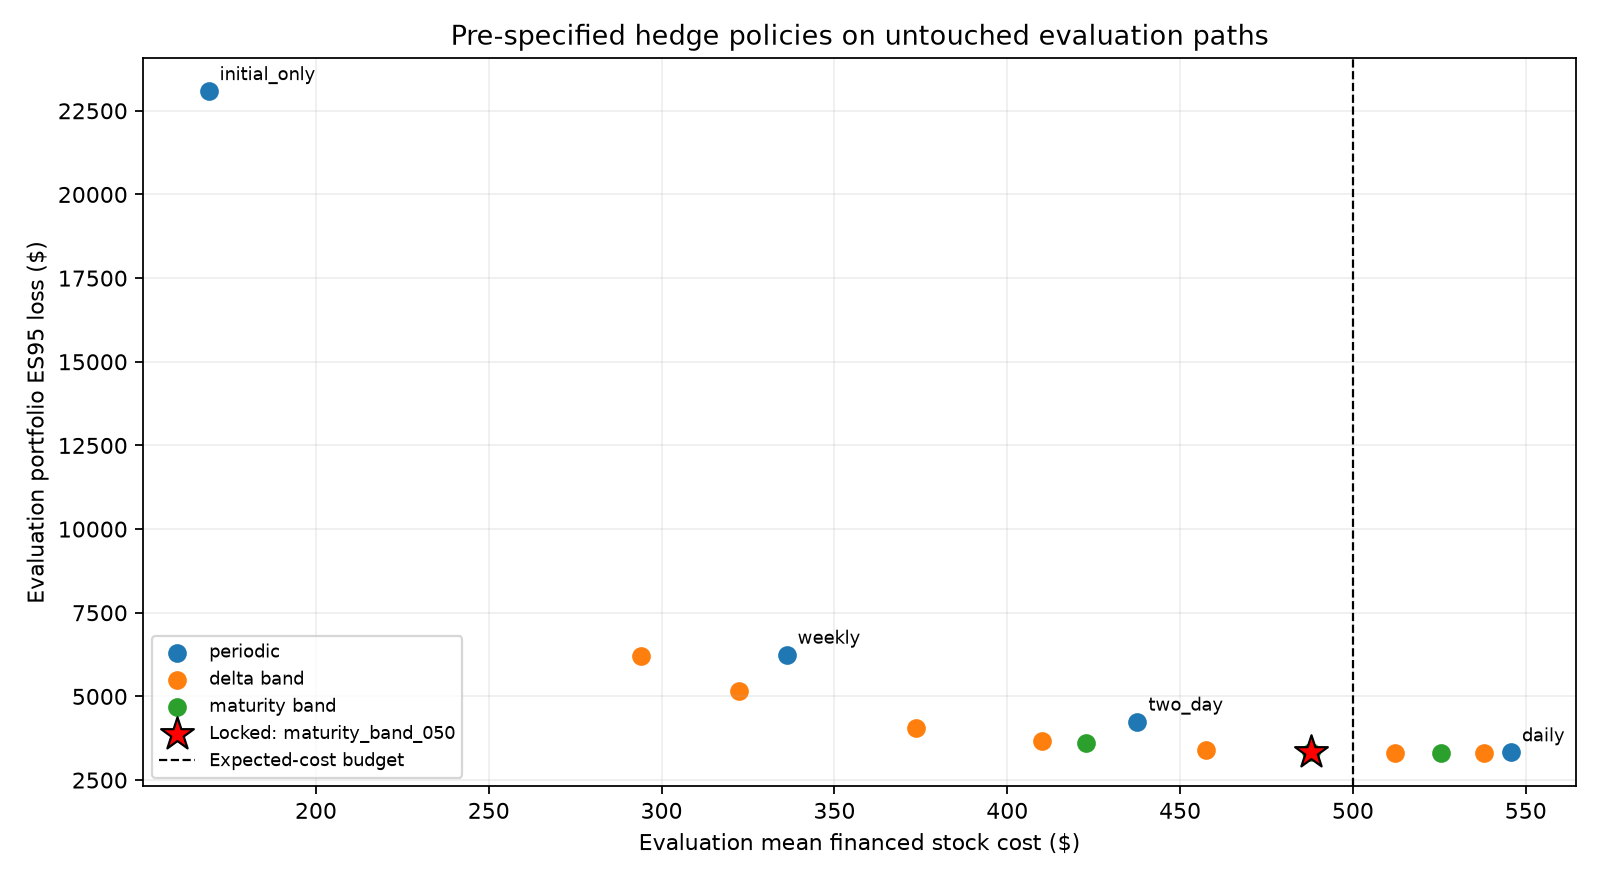

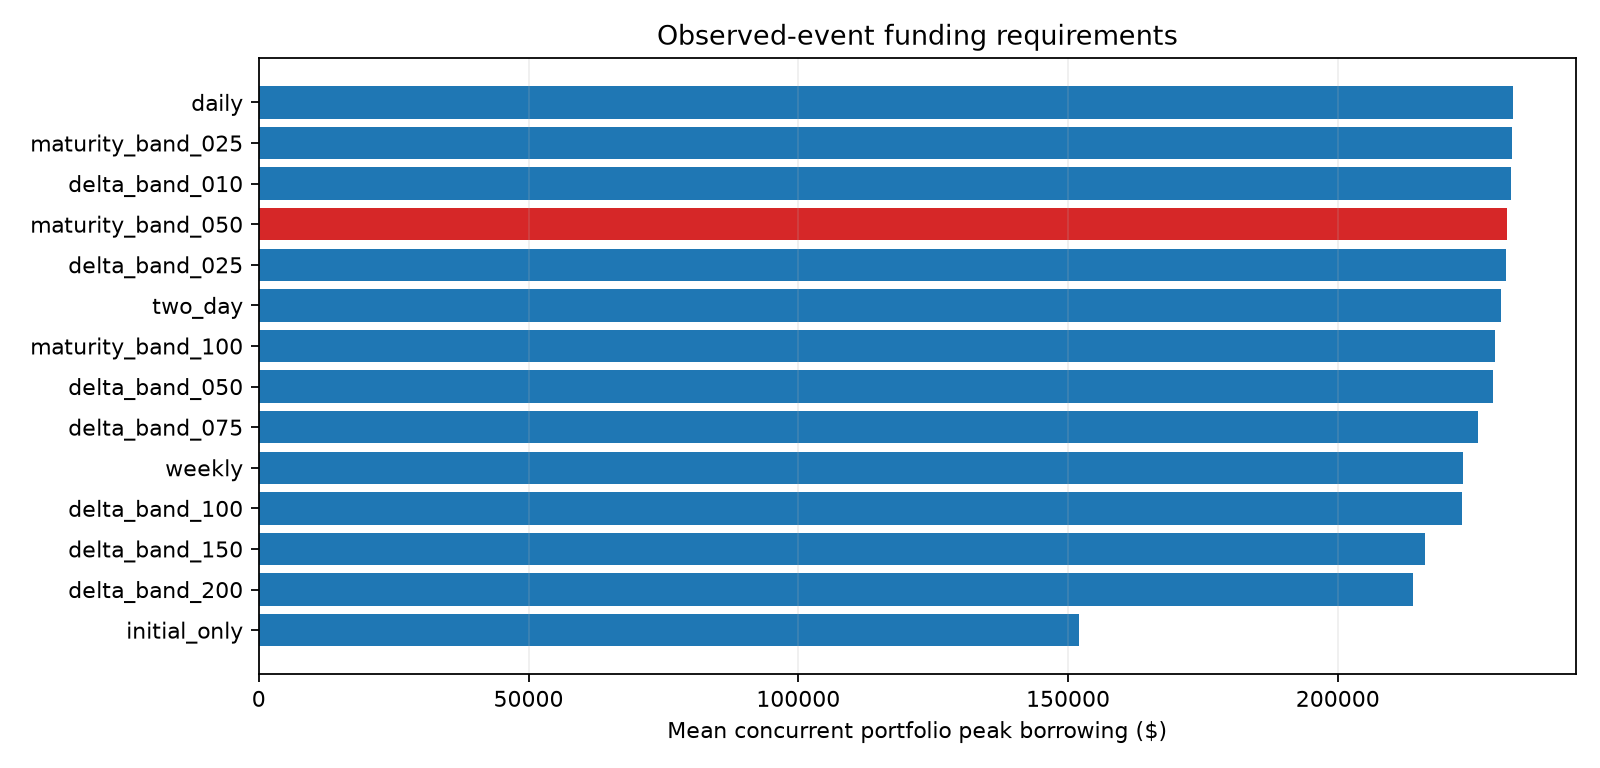

,policy,mean_turnover,mean_trades,mean_peak_borrowing,peak_borrowing_p95,max_peak_borrowing
0,initial_only,336149.503,6.000,152049.273,152049.273,152049.273
1,daily,1085974.710,190.649,232527.879,301043.065,305716.441
2,two_day,870974.083,98.252,230211.086,301432.306,307969.894
3,weekly,669004.629,41.890,223290.042,301705.535,309095.318
4,delta_band_010,1070782.177,142.890,232100.582,299870.196,305665.221
5,delta_band_025,1019122.140,107.425,231098.238,298241.066,304003.321
6,delta_band_050,910805.442,68.760,228777.276,295728.869,302043.262
7,delta_band_075,816312.414,47.052,225977.324,293052.455,300850.473
8,delta_band_100,743587.814,34.566,222994.144,289989.525,301872.416
9,delta_band_150,641744.949,21.998,216098.112,280503.104,306943.491


In [6]:
display(Image(filename=str(RELEASE_DIR / "cost_risk.png")))
display(Image(filename=str(RELEASE_DIR / "peak_funding.png")))
display(evaluation[["policy", "mean_turnover", "mean_trades", "mean_peak_borrowing", "peak_borrowing_p95", "max_peak_borrowing"]].round(3))

## 6 · Inspect completion evidence and limits

All twenty-eight selection/evaluation ledgers reconcile cash, marked value, final settlement and financed costs. The complete gate marker is written only after plots and report succeed. Source, configuration and selection-lock hashes are recorded in the release artifacts. Independent validation separately reproduces all cases and paired intervals.

This completes Research Gate 1 for the illustrative controlled study. Later stages require actual data coverage, historical accounting, release-aware forecasts, equity overlays and conditional/survivorship-aware breadth. Human review remains a separate step.

The full standalone report is `report.md` in the verified release directory. The independent audit is `docs/independent_validation.md`.

In [7]:
display(pd.read_csv(RELEASE_DIR / "accounting_checks.csv").round(10))
print(json.dumps(gate, indent=2))
chosen = evaluation.loc[evaluation["policy"].eq(selected)].iloc[0]
print(f"Locked policy {selected}: ES95 ${chosen['loss_es95']:,.2f}; expected financed cost ${chosen['mean_financed_cost']:,.2f}")
print("Standalone report:", RELEASE_DIR / "report.md")
print("Independent validation:", ROOT / "docs" / "independent_validation.md")

,sample,policy,max_cash_residual,max_marked_value_residual,max_financed_cost_residual,audit_final_cash
0,selection,initial_only,0.000000e+00,0.0,0.000000e+00,-19108.327432
1,selection,daily,0.000000e+00,0.0,2.000000e-10,-891.460540
2,selection,two_day,0.000000e+00,0.0,2.000000e-10,-878.718103
3,selection,weekly,0.000000e+00,0.0,2.000000e-10,-949.003555
4,selection,delta_band_010,0.000000e+00,0.0,3.000000e-10,-984.203773
5,selection,delta_band_025,0.000000e+00,0.0,2.000000e-10,-989.572359
6,selection,delta_band_050,0.000000e+00,0.0,2.000000e-10,-841.717025
7,selection,delta_band_075,0.000000e+00,0.0,2.000000e-10,-1298.014605
8,selection,delta_band_100,0.000000e+00,0.0,2.000000e-10,-1100.038500
9,selection,delta_band_150,0.000000e+00,0.0,2.000000e-10,-1744.357344


{
  "gate": "research_gate_1",
  "status": "complete",
  "human_review": "pending_separate_review",
  "scope": "controlled synthetic policy-selection study only",
  "selected_policy": "maturity_band_050",
  "selected_evaluation_budget_feasible": true,
  "selection_locked_before_evaluation": true,
  "selection_lock_sha256": "c0dd334985d7bf3f2ad1e3512c6e447a6c19df07cda22ec0e5677936b8d0e01c",
  "accounting_checks_passed": true,
  "tail_uncertainty_reported": true,
  "peak_financing_reported": true,
  "market_or_stage7_gate_passed": false
}
Locked policy maturity_band_050: ES95 $3,327.94; expected financed cost $487.97
Standalone report: /Users/saireddivari/MonteCarloEvaluations/results/research-release-1/release-1/report.md
Independent validation: /Users/saireddivari/MonteCarloEvaluations/docs/independent_validation.md
